# Notebook 8: Annotation validation (fills the [n] values of Table 2)

| Part | What it does | When |
|---|---|---|
| **A** | Draws a stratified sample of 300 images (25 per class and subset) and writes `annotation_sample.zip` with the images renamed `A001.jpg ... A300.jpg` (no labels) and an empty sheet `annotation_sheet.csv` | Run first, give the zip to the second annotator |
| **B** | Reads the filled sheet and computes agreement and Cohen's kappa for class and subset, and lists every disagreement | After the annotator returns the sheet |
| **C** | Lists every test image misclassified by any recipe-F model in any scenario and draws them with true and predicted class, for the post-hoc review | Any time |

## Inputs (Add Input)
- Stage 0 output (images, `manifest.csv`)
- Notebook 2 output, final version (needed for Part C only)
- For Part B: the filled `annotation_sheet.csv`, uploaded as a small Kaggle dataset (Add Input -> Your Datasets)

## How the second annotator fills the sheet
Open `annotation_sheet.csv` in Excel. For each file `A001.jpg ...` write the class in `class_2` (Churi, Dao, Khor, Kodal, Kural or Shabol) and `single` or `multi` in `subset_2`. The annotator must not see the original labels. Save as CSV with the same name.

In [1]:
import os, json, zipfile, random
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from sklearn.metrics import cohen_kappa_score

ON_KAGGLE = Path("/kaggle/input").is_dir()
INPUT_ROOT = Path("/kaggle/input") if ON_KAGGLE else Path(r"H:\BD Weapon Inputs")
OUT = (Path("/kaggle/working") if ON_KAGGLE else Path(r"H:\BD Weapon Analysis")) / "annotation_validation"
OUT.mkdir(parents=True, exist_ok=True)
N_PER_CELL, SEED = 25, 42          # 25 x 6 classes x 2 subsets = 300 images

def walk_find(base, predicate, skip=("standardized", "cutouts", "masks", "figures", "weights")):
    for dirpath, dirnames, filenames in os.walk(base, followlinks=True):
        hit = predicate(Path(dirpath), filenames)
        if hit:
            return hit
        dirnames[:] = [x for x in dirnames if x not in skip]
    return None

STAGE0 = walk_find(INPUT_ROOT, lambda d, f: d.parent if ("manifest.csv" in f and d.name == "metadata"
                                                        and d.parent.name == "stage0") else None)
assert STAGE0, "Stage 0 output not found (Add Input -> Your Work -> Stage 0 notebook)."
manifest = pd.read_csv(STAGE0 / "metadata" / "manifest.csv", dtype={"image_id": str})
CLASSES = sorted(manifest.label.unique())
print("Stage 0:", STAGE0, "|", len(manifest), "images |", CLASSES)

Stage 0: /kaggle/input/notebooks/arnicasarker/stage0-single-multi-3parts/stage0 | 2950 images | ['Churi', 'Dao', 'Khor', 'Kodal', 'Kural', 'Shabol']


## Part A: sample for the second annotator

In [2]:
sample = pd.concat([g.sample(min(N_PER_CELL, len(g)), random_state=SEED)
                    for _, g in manifest.groupby(["label", "subset"])])
sample = sample.sample(frac=1, random_state=SEED).reset_index(drop=True)   # shuffled: labels cannot be guessed from order
sample["file"] = [f"A{i + 1:03d}.jpg" for i in range(len(sample))]

z_path = OUT / "annotation_sample.zip"
with zipfile.ZipFile(z_path, "w", zipfile.ZIP_DEFLATED) as z:
    for r in sample.itertuples():
        im = Image.open(STAGE0 / r.path).convert("RGB"); im.thumbnail((1280, 1280))
        tmp = OUT / r.file; im.save(tmp, quality=92); z.write(tmp, f"images/{r.file}"); tmp.unlink()
    sheet = sample[["file"]].assign(class_2="", subset_2="")
    sheet.to_csv(OUT / "annotation_sheet.csv", index=False); z.write(OUT / "annotation_sheet.csv", "annotation_sheet.csv")
# private key (do NOT give to the annotator)
sample[["file", "image_id", "label", "subset"]].to_csv(OUT / "annotation_key_PRIVATE.csv", index=False)
print(f"{len(sample)} images written to {z_path}")
print("Give ONLY annotation_sample.zip to the second annotator; keep annotation_key_PRIVATE.csv.")
display(sample.groupby(["label", "subset"]).size().unstack())

300 images written to /kaggle/working/annotation_validation/annotation_sample.zip
Give ONLY annotation_sample.zip to the second annotator; keep annotation_key_PRIVATE.csv.


subset,multi,single
label,,
Churi,25,25
Dao,25,25
Khor,25,25
Kodal,25,25
Kural,25,25
Shabol,25,25


## Part B: agreement (run after the filled sheet is attached)

,label,images,raw_agreement,cohen_kappa,disagreements
0,class,300,0.98,0.976,6
1,subset,300,0.99,0.980,3


annotator 2  Churi  Dao  Khor  Kodal  Kural  Shabol
annotator 1                                        
Churi           50    0     0      0      0       0
Dao              0   50     0      0      0       0
Khor             0    0    49      1      0       0
Kodal            0    0     0     50      0       0
Kural            0    0     0      0     45       5
Shabol           0    0     0      0      0      50
Disagreements saved to disagreements.csv (9 images). Review them: each one you correct counts as 'Changed'.


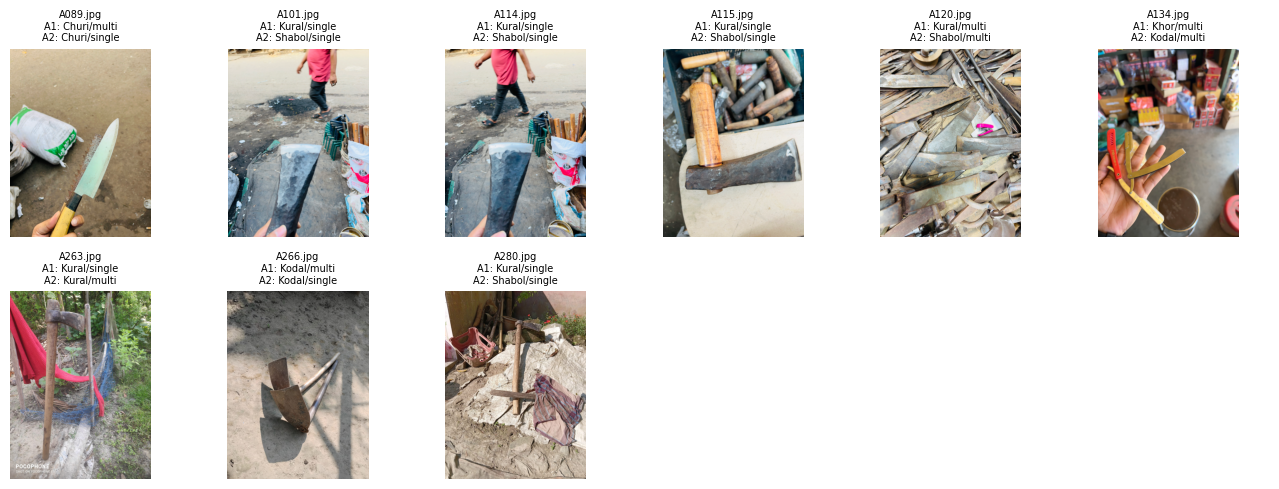

In [3]:
filled = walk_find(INPUT_ROOT, lambda d, f: d / "annotation_sheet.csv" if "annotation_sheet.csv" in f else None)
key_p = OUT / "annotation_key_PRIVATE.csv"
if filled is None or not key_p.exists():
    print("Part B skipped: attach the filled annotation_sheet.csv (and run Part A in this session to recreate the key).")
else:
    key = pd.read_csv(key_p, dtype={"image_id": str})
    sh = pd.read_csv(filled).merge(key, on="file")
    norm_c = {c.lower(): c for c in CLASSES}
    sh["class_2"] = sh.class_2.astype(str).str.strip().str.lower().map(norm_c)
    sh["subset_2"] = sh.subset_2.astype(str).str.strip().str.lower()
    miss = sh.class_2.isna() | ~sh.subset_2.isin(["single", "multi"])
    if miss.any():
        print(f"{miss.sum()} rows have an empty or invalid entry and are excluded:", sh[miss].file.tolist()[:20])
    sh = sh[~miss]
    res = []
    for name, a, b in [("class", "label", "class_2"), ("subset", "subset", "subset_2")]:
        dis = (sh[a] != sh[b]).sum()
        res.append({"label": name, "images": len(sh), "raw_agreement": (sh[a] == sh[b]).mean(),
                    "cohen_kappa": cohen_kappa_score(sh[a], sh[b]), "disagreements": int(dis)})
    res = pd.DataFrame(res); display(res.round(3)); res.round(4).to_csv(OUT / "agreement.csv", index=False)
    print(pd.crosstab(sh.label, sh.class_2, rownames=["annotator 1"], colnames=["annotator 2"]))
    dis = sh[(sh.label != sh.class_2) | (sh.subset != sh.subset_2)]
    dis.to_csv(OUT / "disagreements.csv", index=False)
    print(f"Disagreements saved to disagreements.csv ({len(dis)} images). Review them: each one you correct counts as 'Changed'.")
    if len(dis):
        n = min(len(dis), 24); cols = 6; rows = int(np.ceil(n / cols))
        fig, axes = plt.subplots(rows, cols, figsize=(2.2 * cols, 2.5 * rows), squeeze=False)
        for ax in axes.ravel(): ax.axis("off")
        for ax, r in zip(axes.ravel(), dis.head(n).itertuples()):
            row = manifest[manifest.image_id == r.image_id].iloc[0]
            ax.imshow(Image.open(STAGE0 / row.path).convert("RGB"))
            ax.set_title(f"{r.file}\nA1: {r.label}/{r.subset}\nA2: {r.class_2}/{r.subset_2}", fontsize=7)
        fig.tight_layout(); fig.savefig(OUT / "disagreements.png", dpi=150); plt.show()

## Part C: post-hoc review of misclassified test images

Misclassified test images (any model, any scenario): 4  ->  'Flagged' in Table 2


,image_id,true,models,scenarios,predicted
0,3880e241521f,Kodal,resnet50,single,Kural
1,3b2b02d1c68a,Kodal,"convnext_tiny, resnet50","all, single",Dao
2,86592ae7378d,Kural,resnet50,multi,Shabol
3,cf6567946825,Churi,"convnext_tiny, resnet50, vit_small_patch16_224",single,Kodal


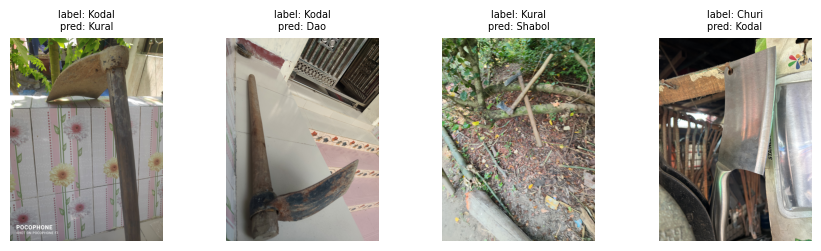

Look at each image: if the label is right, the error is the model's (Changed = 0 for that image).
Results zipped: /kaggle/working/annotation_validation_results.zip


In [4]:
NB2 = walk_find(INPUT_ROOT, lambda d, f: d if (d.name == "results" and any((d / s / "summary_all.csv").exists()
                                                                            for s in ("all", "single", "multi"))) else None)
if NB2 is None:
    print("Part C skipped: attach the Notebook 2 output.")
else:
    rows = []
    for f in NB2.glob("*/*/F/test_predictions.csv"):
        sc, model = f.parts[-4], f.parts[-3]
        d = pd.read_csv(f, dtype={"image_id": str})
        inv = {i: c for i, c in enumerate(CLASSES)}
        for r in d[d.y != d.pred].itertuples():
            rows.append({"image_id": r.image_id, "scenario": sc, "model": model,
                         "true": inv[r.y], "predicted": inv[r.pred]})
    err = pd.DataFrame(rows)
    if err.empty:
        print("No misclassified test image in any recipe-F model.")
    else:
        per_img = (err.groupby(["image_id", "true"])
                   .agg(models=("model", lambda x: ", ".join(sorted(set(x)))),
                        scenarios=("scenario", lambda x: ", ".join(sorted(set(x)))),
                        predicted=("predicted", lambda x: ", ".join(sorted(set(x))))).reset_index())
        per_img.to_csv(OUT / "posthoc_misclassified.csv", index=False)
        print(f"Misclassified test images (any model, any scenario): {len(per_img)}  ->  'Flagged' in Table 2")
        display(per_img)
        n = len(per_img); cols = min(6, n); rows_ = int(np.ceil(n / cols))
        fig, axes = plt.subplots(rows_, cols, figsize=(2.2 * cols, 2.6 * rows_), squeeze=False)
        for ax in axes.ravel(): ax.axis("off")
        for ax, r in zip(axes.ravel(), per_img.itertuples()):
            row = manifest[manifest.image_id == r.image_id].iloc[0]
            ax.imshow(Image.open(STAGE0 / row.path).convert("RGB"))
            ax.set_title(f"label: {r.true}\npred: {r.predicted}", fontsize=7)
        fig.tight_layout(); fig.savefig(OUT / "posthoc_misclassified.png", dpi=150); plt.show()
        print("Look at each image: if the label is right, the error is the model's (Changed = 0 for that image).")

with zipfile.ZipFile(OUT.parent / "annotation_validation_results.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for f in OUT.iterdir():
        if f.name != "annotation_sample.zip":
            z.write(f, f.name)
print("Results zipped: /kaggle/working/annotation_validation_results.zip")